# **Phase 2 - Transfer Learning & Data Augmentations**

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

In [1]:
import torch, torch.nn as nn, torchvision, time, os, copy, random
import torchvision.models as models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device)

Device: cuda


## **Overview**
1. CIFAR10 Dataset
2. Data Augmentations
3. Transfer learning with ResNet Architecture
4. Training ResNet Architecture

# **1. CIFAR10 Dataset**

This is an RGB dataset with 10 classes:

*plane, car, bird, cat, deer, dog, frog, horse, ship, truck*


## **1.1 Download and Load CIFAR10**

You can find CIFAR10 in ```torchvision.datasets.CIFAR10()``` or see [here](https://pytorch.org/vision/0.15/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10). Please Download the dataset and use Dataloaders to load it. This is identical to loading MNIST.

In [2]:
transform=transforms.Compose([transforms.ToTensor(),
 transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size=64
train_set=datasets.CIFAR10(root='./data',train=True,download=True,transform=transform)
train_loader=DataLoader(train_set,batch_size=batch_size,shuffle=True,num_workers=0)
testset=datasets.CIFAR10(root='./data',train=False,download=True,transform=transform)
test_loader=DataLoader(testset,batch_size=batch_size,shuffle=False,num_workers=0)
classes=('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

100%|██████████| 170M/170M [00:07<00:00, 23.5MB/s]


## **1.2 Display CIFAR10 Images**

Similar to Phase 1, please complete `show_imgs()` function to display 10 images. However, this time we want to display exactly one image per class. There are 10 classes total. Show a random image per class with their label.

In [3]:
def show_imgs(dataloader,classes):
    """Find and show one randomized example for every class."""
    samples={}
    for images,labels in dataloader:
        for img,label in zip(images,labels):
            k=int(label)
            if k not in samples: samples[k]=img
        if len(samples)==len(classes): break
    fig,axes=plt.subplots(2,5,figsize=(12,5))
    for k,ax in enumerate(axes.flat):
        img=samples[k].detach().cpu()*0.5+0.5
        ax.imshow(img.permute(1,2,0).clamp(0,1))
        ax.set_title(classes[k]);ax.axis('off')
    plt.tight_layout();plt.show()

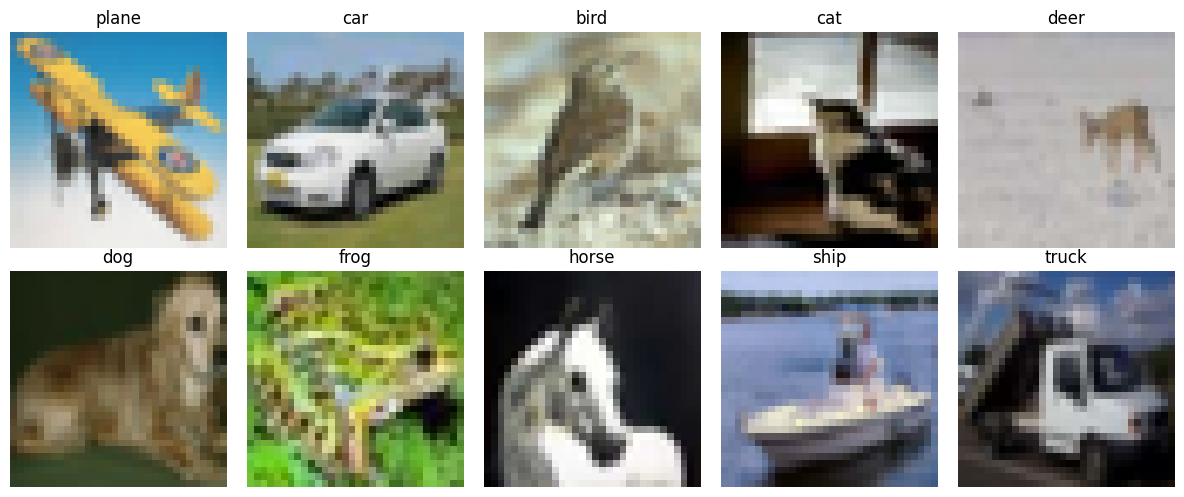

In [4]:
show_imgs(train_loader, classes)

# **2. Data Augmentations**

## **2.1 Use Built-in Augmentations**

Use augmentations from the `torchvision.transforms` library [
link](https://pytorch.org/vision/0.9/transforms.html). Apply the following. For the parameters, please test and choose suitable ones.


*   Horizontal Flip
*   Random Crop
*   Color Jitter
*   Random Resized Crop

Try each of these individually and display the augmented images using your `show_imgs()` function.

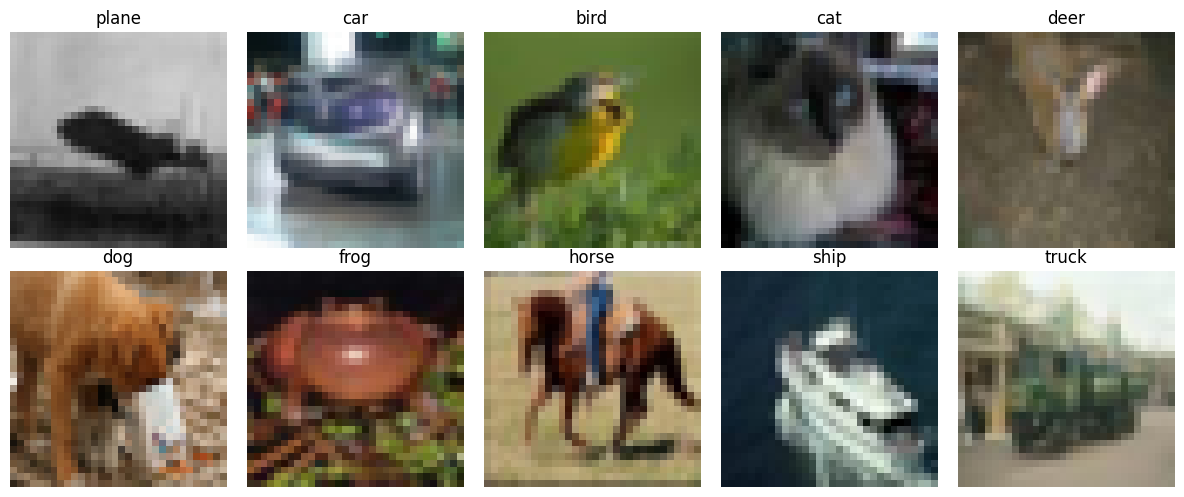

In [5]:
# Visualize one augmentation in isolation.
aug_transform=transforms.Compose([transforms.RandomHorizontalFlip(p=0.5),transforms.ToTensor(),
  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
train_aug_set=datasets.CIFAR10(root='./data',train=True,download=False,transform=aug_transform)
train_aug_loader=DataLoader(train_aug_set,batch_size=batch_size,shuffle=True,num_workers=0)
show_imgs(train_aug_loader,classes)

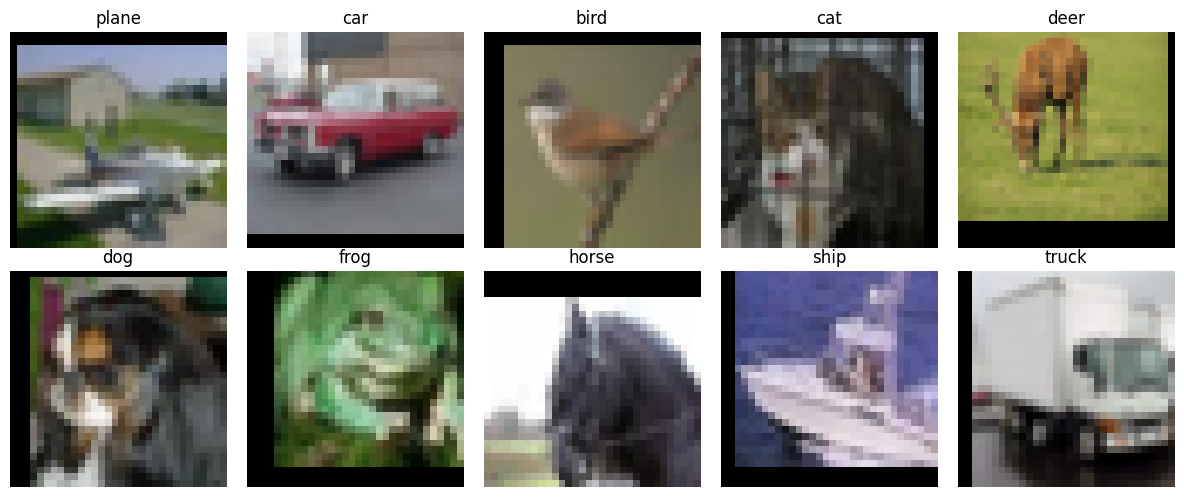

In [6]:
# Visualize one augmentation in isolation.
aug_transform=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.ToTensor(),
  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
train_aug_set=datasets.CIFAR10(root='./data',train=True,download=False,transform=aug_transform)
train_aug_loader=DataLoader(train_aug_set,batch_size=batch_size,shuffle=True,num_workers=0)
show_imgs(train_aug_loader,classes)

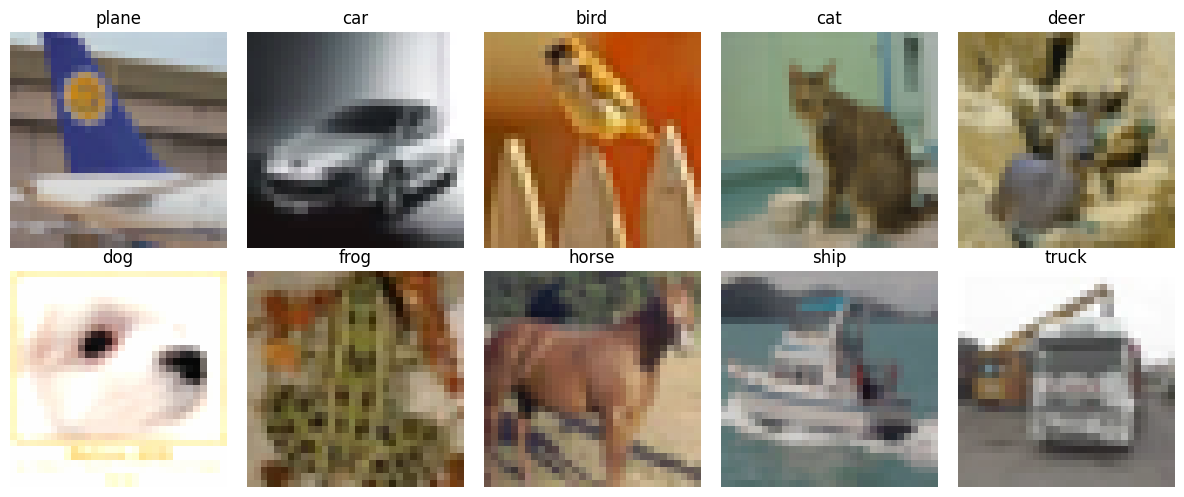

In [7]:
# Visualize one augmentation in isolation.
aug_transform=transforms.Compose([transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2,hue=0.05),transforms.ToTensor(),
  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
train_aug_set=datasets.CIFAR10(root='./data',train=True,download=False,transform=aug_transform)
train_aug_loader=DataLoader(train_aug_set,batch_size=batch_size,shuffle=True,num_workers=0)
show_imgs(train_aug_loader,classes)

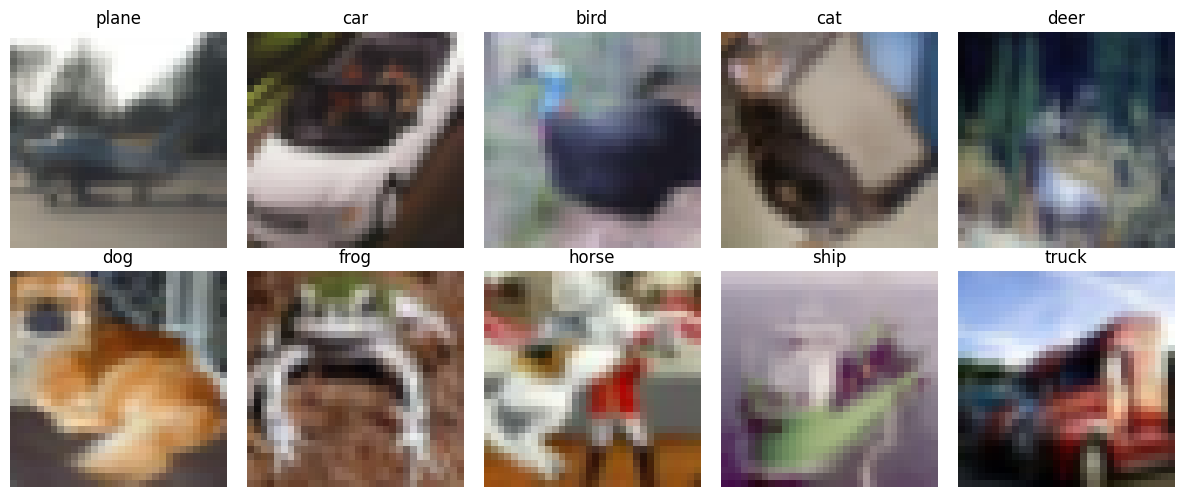

In [8]:
# Visualize one augmentation in isolation.
aug_transform=transforms.Compose([transforms.RandomResizedCrop(32,scale=(0.75,1.0),ratio=(0.9,1.1)),transforms.ToTensor(),
  transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
train_aug_set=datasets.CIFAR10(root='./data',train=True,download=False,transform=aug_transform)
train_aug_loader=DataLoader(train_aug_set,batch_size=batch_size,shuffle=True,num_workers=0)
show_imgs(train_aug_loader,classes)

### ❓ **Q 2.1.1 Please explain what Data augmentations are and their use. What is the purpose of making them random?**

**Answer:** Data augmentation creates label-preserving variants of training images to improve generalization. Randomness means each epoch can expose a new variant, reducing memorization and making the model robust to natural changes in appearance, orientation, and cropping. Augmentation is applied only to the training split, not the evaluation split.

___
### ❓ **Q 2.1.2 Please explain all of the augmentations you are using. What is the value of each of them?**

**Answer:** HorizontalFlip(p=0.5) mirrors a picture left/right, useful because object identity usually survives reflection. RandomCrop(32,padding=4) translates the object and strengthens location robustness. ColorJitter(0.2 brightness/contrast/saturation, 0.05 hue) simulates different illumination and camera colors. RandomResizedCrop(32, scale 0.75–1.0) varies crop and object scale while retaining most of the image. Excessive augmentation can remove discriminative content and hurt performance.

## **2.2 Custom Augmentations**

Create a custom data augmentation function. Please do rotation, randomly between -30 and 30 degrees. You must code this yourself, do not use the torchvision function.

[This tutorial ](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) may be useful. You can use `PIL` image manupilation libraries, but NOT torchvision ones. Do not import any other libraries. You should only need:



```
from PIL import Image
import random
```





Apply this custom augmentation to the images and display the results using `show_imgs()`.

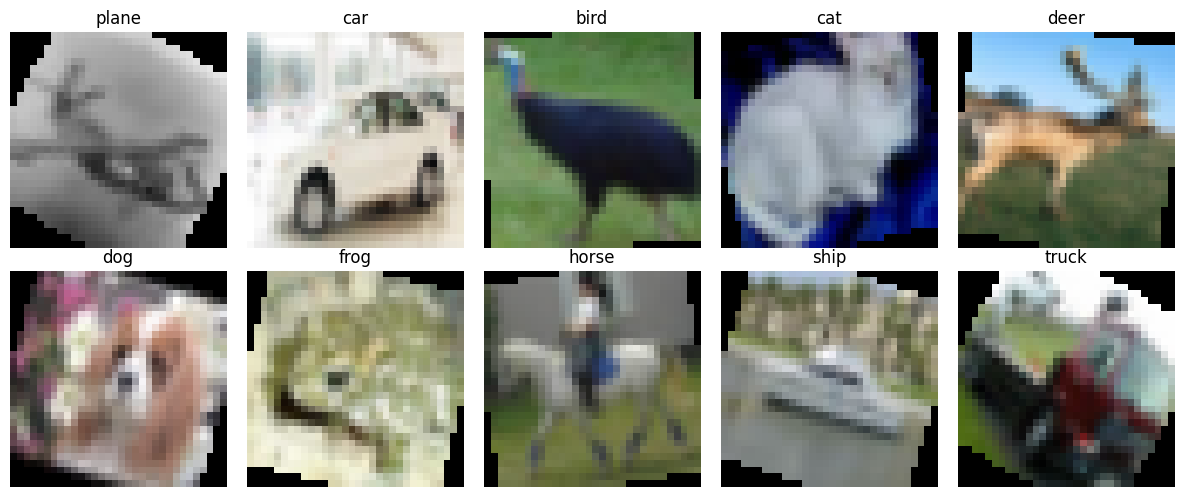

In [9]:
from PIL import Image
import random
class RandomRotate:
    def __init__(self,min_degrees=-30,max_degrees=30):
        self.low,self.high=min_degrees,max_degrees
    def __call__(self,image):
        angle=random.uniform(self.low,self.high)
        return image.rotate(angle,resample=Image.Resampling.BILINEAR)
rotate_transform=transforms.Compose([RandomRotate(-30,30),transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
train_rotate_set=datasets.CIFAR10(root='./data',train=True,download=False,transform=rotate_transform)
train_loader_rotate=DataLoader(train_rotate_set,batch_size=batch_size,shuffle=True,num_workers=0)
show_imgs(train_loader_rotate,classes)

### ❓ **Q 2.2.1 Explain how you would determine what is a good lower and upper limit for rotation? We use -30 to 30, why does that make sense?**

**Answer:** Select limits by looking at plausible real-world camera/object rotations, visualizing samples, and measuring validation accuracy across trial ranges (for example ±10°, ±20°, ±30°, ±45°). ±30° is a moderate rotation that retains many recognizable CIFAR objects while promoting viewpoint robustness. Some classes, such as planes and trucks, may lose realism at very large rotations; the best range should be chosen by validation performance.

____

# **3. Transfer Learning**
Load ResNet18 model from ```torchvision.models.resnet18()```, make sure to load pretrained model with [weights](https://pytorch.org/vision/stable/models.html).
You will need to modify the final layer. ResNet outputs 100 labels - please change to the correct output dimension.

## **3.1 ResNet18**

In [10]:
from torchvision.models import resnet18, ResNet18_Weights
# Downloading ImageNet weights requires internet on the first run.
def new_resnet():
    m=resnet18(weights=ResNet18_Weights.DEFAULT)
    m.fc=nn.Linear(m.fc.in_features,len(classes))
    return m.to(device)
resnet18=new_resnet()
print(resnet18)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## **3.2 Train ResNet on CIFAR10**

### **3.2.1 Train and Test Functions**
You can refer to Phase_1.ipynb to complete these functions. In ```train()```, rather than saving the accuracy and loss per iteration, you will need to save the loss and accuracy ***per epoch***. Plot loss and accuracy plots for both train and validation sets.

In [11]:
def train(model,loss_fn,optimizer,train_loader,test_loader,num_epochs=10,device=device):
    history={k:[] for k in ('train_loss','train_acc','test_loss','test_acc','seconds')}
    model.to(device)
    for ep in range(num_epochs):
        start=time.perf_counter()
        for split,loader in (('train',train_loader),('test',test_loader)):
            is_training=split=='train'
            model.train(is_training)
            total=correct=0;sum_loss=0.
            with torch.set_grad_enabled(is_training):
                for x,y in loader:
                    x,y=x.to(device),y.to(device)
                    if is_training: optimizer.zero_grad(set_to_none=True)
                    outputs=model(x); loss=loss_fn(outputs,y)
                    if is_training: loss.backward();optimizer.step()
                    sum_loss+=loss.item()*y.size(0)
                    correct+=(outputs.argmax(1)==y).sum().item();total+=y.size(0)
            history[f'{split}_loss'].append(sum_loss/max(total,1))
            history[f'{split}_acc'].append(correct/max(total,1))
        elapsed=time.perf_counter()-start
        history['seconds'].append(elapsed)
        print(f'Epoch {ep+1:02d}/{num_epochs}: '
              f'train loss {history["train_loss"][-1]:.4f}, acc {history["train_acc"][-1]:.2%}; '
              f'validation loss {history["test_loss"][-1]:.4f}, acc {history["test_acc"][-1]:.2%}; {elapsed:.1f}s')
    return history
@torch.no_grad()
def test_accuracy(model,loader,device=device):
    model.eval();correct=total=0
    for x,y in loader:
        y=y.to(device);out=model(x.to(device));correct+=(out.argmax(1)==y).sum().item();total+=len(y)
    print(f'Accuracy: {correct/max(total,1):.2%}')
    return correct/max(total,1)
def plot_learning_curve(h,title='ResNet18'):
    ep=range(1,len(h['train_loss'])+1)
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    for split in ('train','test'):
        ax[0].plot(ep,h[f'{split}_loss'],marker='o',label=split)
        ax[1].plot(ep,h[f'{split}_acc'],marker='o',label=split)
    ax[0].set(xlabel='Epoch',ylabel='Cross-entropy',title='Loss')
    ax[1].set(xlabel='Epoch',ylabel='Accuracy',title='Accuracy',ylim=(0,1))
    for a in ax:a.grid(alpha=.2);a.legend()
    fig.suptitle(title);plt.tight_layout();plt.show()
# Shared comparison settings
LEARNING_RATE=1e-4
NUM_EPOCHS=10
# A separate validation split of the training set is preferable for model selection;
# the supplied template uses test_loader for its plots.

### **3.2.2 Train and Plot Learning Curves**

Retrain the ResNet18 on CIFAR10 Dataset. You can chose the optimizer and loss function. Train first with then without data augmentation to compare. When using data augmentations, you can choose which augmentations to use!

Epoch 01/10: train loss 0.9936, acc 65.65%; validation loss 0.6801, acc 76.46%; 31.4s
Epoch 02/10: train loss 0.5733, acc 80.15%; validation loss 0.5950, acc 79.70%; 27.8s
Epoch 03/10: train loss 0.4112, acc 85.79%; validation loss 0.5921, acc 80.33%; 28.3s
Epoch 04/10: train loss 0.2910, acc 89.92%; validation loss 0.6025, acc 80.78%; 27.4s
Epoch 05/10: train loss 0.2085, acc 92.55%; validation loss 0.6489, acc 81.26%; 27.8s
Epoch 06/10: train loss 0.1594, acc 94.38%; validation loss 0.6882, acc 81.24%; 27.9s
Epoch 07/10: train loss 0.1271, acc 95.58%; validation loss 0.7214, acc 80.97%; 28.0s
Epoch 08/10: train loss 0.1051, acc 96.34%; validation loss 0.7776, acc 80.71%; 27.8s
Epoch 09/10: train loss 0.0919, acc 96.86%; validation loss 0.7574, acc 81.49%; 28.1s
Epoch 10/10: train loss 0.0794, acc 97.28%; validation loss 0.7880, acc 81.96%; 28.0s


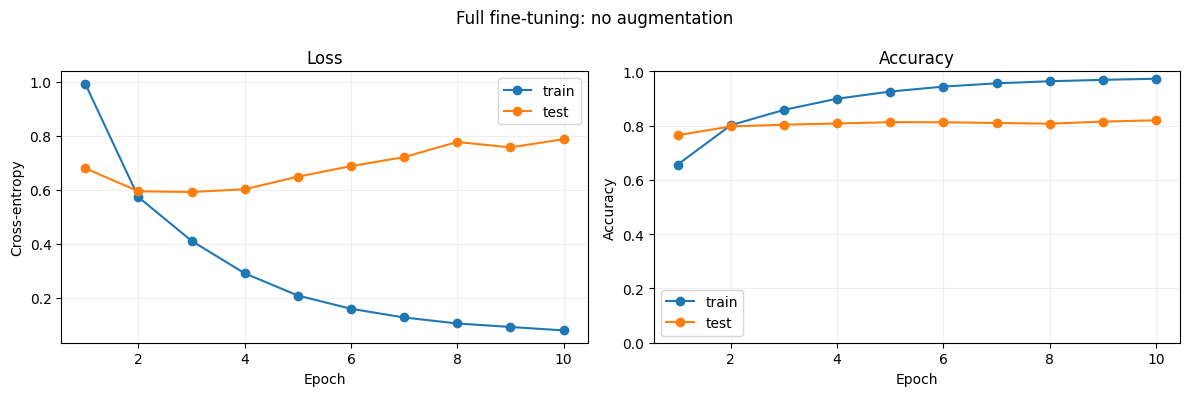

Accuracy: 81.96%


0.8196

In [13]:
from torchvision.models import resnet18
# Full-network fine-tuning without augmentation.
num_epochs=NUM_EPOCHS
model_plain=new_resnet()
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model_plain.parameters(),lr=LEARNING_RATE)
history_plain=train(model_plain,loss_fn,optimizer,train_loader,test_loader,num_epochs,device)
plot_learning_curve(history_plain,'Full fine-tuning: no augmentation')
test_accuracy(model_plain,test_loader)

Epoch 01/10: train loss 1.1510, acc 59.80%; validation loss 0.7616, acc 73.34%; 56.0s
Epoch 02/10: train loss 0.7803, acc 72.73%; validation loss 0.6476, acc 77.57%; 55.5s
Epoch 03/10: train loss 0.6706, acc 76.74%; validation loss 0.5778, acc 79.78%; 56.4s
Epoch 04/10: train loss 0.5962, acc 79.31%; validation loss 0.5471, acc 81.11%; 57.5s
Epoch 05/10: train loss 0.5498, acc 81.01%; validation loss 0.5226, acc 82.08%; 57.5s
Epoch 06/10: train loss 0.5132, acc 82.13%; validation loss 0.4919, acc 82.53%; 58.3s
Epoch 07/10: train loss 0.4773, acc 83.37%; validation loss 0.4994, acc 82.81%; 62.9s
Epoch 08/10: train loss 0.4474, acc 84.38%; validation loss 0.4839, acc 83.42%; 57.3s
Epoch 09/10: train loss 0.4235, acc 85.10%; validation loss 0.4759, acc 83.87%; 57.6s
Epoch 10/10: train loss 0.4002, acc 86.04%; validation loss 0.4695, acc 84.05%; 55.9s


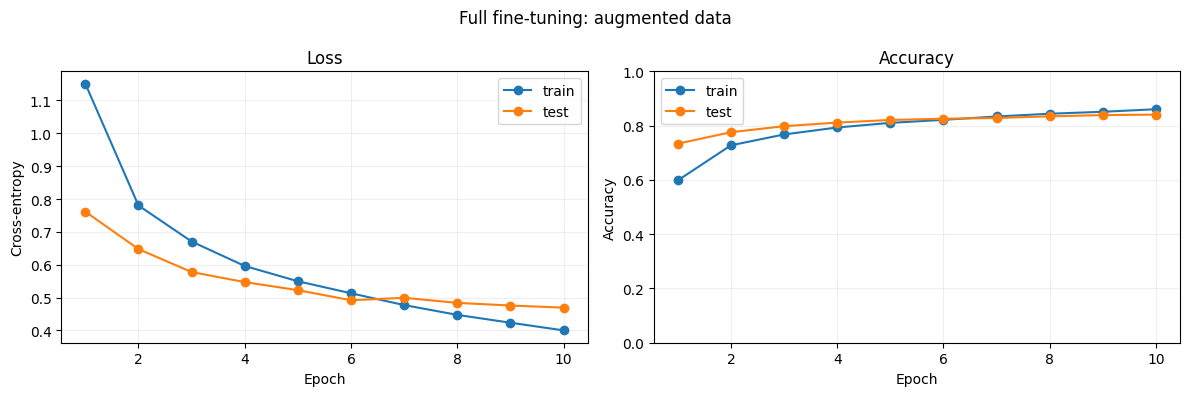

Accuracy: 84.05%


0.8405

In [14]:
# Identical full-network setup, with augmentation of training images only.
train_aug_transform=transforms.Compose([
    transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=.15,contrast=.15,saturation=.15),
    transforms.ToTensor(),transforms.Normalize((.5,.5,.5),(.5,.5,.5))])
train_aug_dataset=datasets.CIFAR10(root='./data',train=True,download=False,transform=train_aug_transform)
train_aug_loader=DataLoader(train_aug_dataset,batch_size=batch_size,shuffle=True,num_workers=0)
num_epochs=NUM_EPOCHS
model_aug=new_resnet()
optimizer=torch.optim.Adam(model_aug.parameters(),lr=LEARNING_RATE)
history_aug=train(model_aug,loss_fn,optimizer,train_aug_loader,test_loader,num_epochs,device)
plot_learning_curve(history_aug,'Full fine-tuning: augmented data')
test_accuracy(model_aug,test_loader)

### **3.2.3 Confusion Matrix**

Write code to plot a confusion matrix after training the above ResNet18. Please make sure the axis have class names (defined in Section 1)

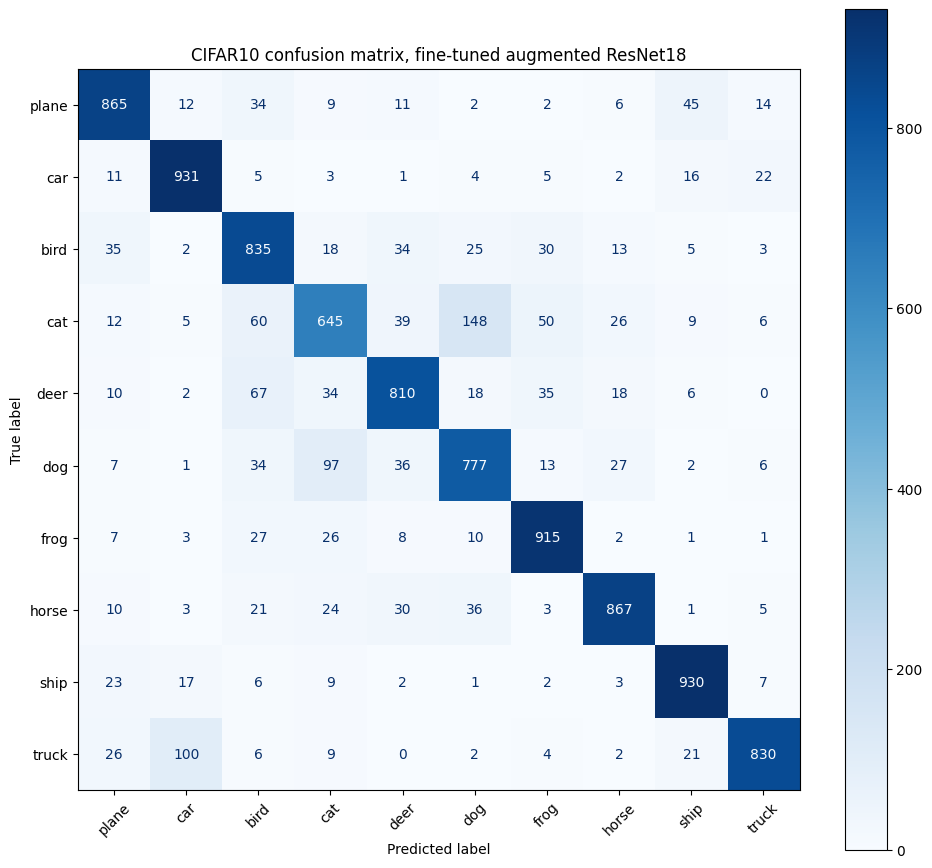

              precision    recall  f1-score   support

       plane       0.86      0.86      0.86      1000
         car       0.87      0.93      0.90      1000
        bird       0.76      0.83      0.80      1000
         cat       0.74      0.65      0.69      1000
        deer       0.83      0.81      0.82      1000
         dog       0.76      0.78      0.77      1000
        frog       0.86      0.92      0.89      1000
       horse       0.90      0.87      0.88      1000
        ship       0.90      0.93      0.91      1000
       truck       0.93      0.83      0.88      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



In [15]:
@torch.no_grad()
def plot_confusion_matrix(model,loader,classes,device=device):
    model.eval();truth=[];prediction=[]
    for x,y in loader:
        out=model(x.to(device))
        truth.extend(y.numpy().tolist());prediction.extend(out.argmax(1).cpu().numpy().tolist())
    cm=confusion_matrix(truth,prediction,labels=list(range(len(classes))))
    fig,ax=plt.subplots(figsize=(10,9))
    ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=45,cmap='Blues',values_format='d')
    plt.title('CIFAR10 confusion matrix, fine-tuned augmented ResNet18')
    plt.tight_layout();plt.show()
    print(classification_report(truth,prediction,target_names=classes,zero_division=0))
    return cm
cm_aug=plot_confusion_matrix(model_aug,test_loader,classes)

## **3.2.4 Freeze Network**

Initialize a new ResNet18, Freeze all the non-linear or non-fc weights. Hence, we will only be training the fc layers.

Freezing implies setting `requires_grad = False` for selected parameters


In [16]:
resnet18_frz=new_resnet()
for p in resnet18_frz.parameters():p.requires_grad=False
for p in resnet18_frz.fc.parameters():p.requires_grad=True
print('Trainable:',sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad))

Trainable: 5130


### **3.2.5 Train frozen ResNet18**

Retrain the frozen ResNet18 now with the same setup as the previous ResNet18 (same batch size, optimizer, learning rate, etc.) for direct comparison. The results may not be as good that is expected.

Epoch 01/10: train loss 2.0797, acc 26.00%; validation loss 1.8598, acc 35.60%; 21.8s
Epoch 02/10: train loss 1.7721, acc 38.76%; validation loss 1.7219, acc 41.10%; 21.9s
Epoch 03/10: train loss 1.6869, acc 41.45%; validation loss 1.6731, acc 42.63%; 22.1s
Epoch 04/10: train loss 1.6478, acc 42.79%; validation loss 1.6388, acc 43.78%; 22.4s
Epoch 05/10: train loss 1.6172, acc 43.94%; validation loss 1.6295, acc 44.08%; 21.9s
Epoch 06/10: train loss 1.5977, acc 44.75%; validation loss 1.6069, acc 45.05%; 22.2s
Epoch 07/10: train loss 1.5859, acc 45.03%; validation loss 1.5962, acc 45.34%; 21.9s
Epoch 08/10: train loss 1.5766, acc 45.42%; validation loss 1.5911, acc 45.70%; 22.0s
Epoch 09/10: train loss 1.5692, acc 45.87%; validation loss 1.5877, acc 45.50%; 22.2s
Epoch 10/10: train loss 1.5558, acc 45.91%; validation loss 1.5801, acc 45.94%; 21.9s


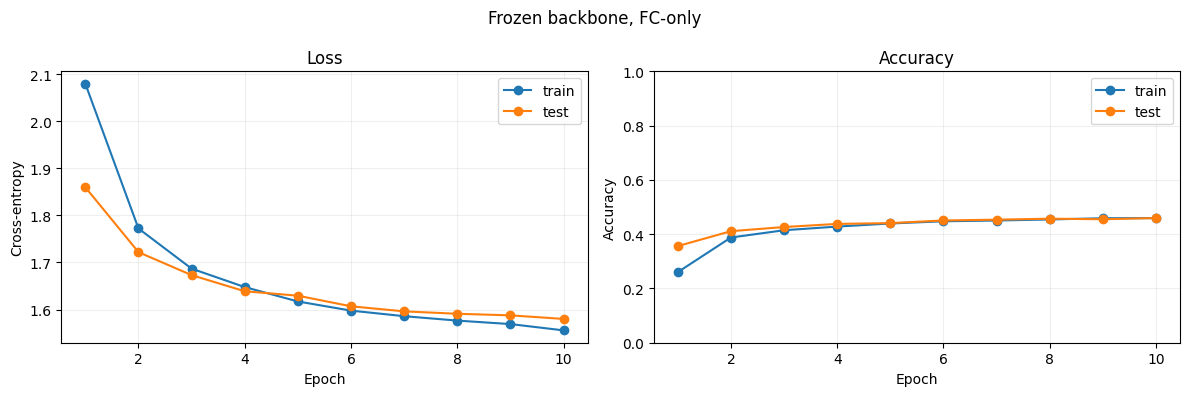

Accuracy: 45.94%


0.4594

In [17]:
num_epochs=NUM_EPOCHS
opt_frozen=torch.optim.Adam(filter(lambda p:p.requires_grad,resnet18_frz.parameters()),lr=LEARNING_RATE)
history_frozen=train(resnet18_frz,loss_fn,opt_frozen,train_loader,test_loader,num_epochs,device)
plot_learning_curve(history_frozen,'Frozen backbone, FC-only')
test_accuracy(resnet18_frz,test_loader)

### ❓ **Q 3.2.6 What was the difference when training with and without data augmentations?**

**Answer:** With the same ResNet18 and 10 training epochs, data augmentation improved the final CIFAR10 test accuracy from **81.96%** (without augmentation) to **84.05%** (with augmentation), a gain of **2.09 percentage points**. As expected, the augmented model had lower training accuracy (**86.04%**, versus **97.28%**) because it learned from harder, randomly modified images. However, it generalized better: its final test loss was **0.4695**, compared with **0.7880** without augmentation. The unaugmented model's test loss began rising as its training loss kept falling, indicating overfitting. Augmentation cost more training time in this run (roughly **56–63 seconds per epoch**, versus **27–31 seconds**), but gave better test performance. Only the training images were randomly augmented.

___
### ❓ **Q 3.2.7 What is transfer learning and why would it be useful?**

**Answer:** Transfer learning starts from weights learned on a large source dataset (ImageNet), then adapts the model to a related task (CIFAR10). Early layers already encode edges, textures and reusable visual features, so a pretrained model often needs less target data and fewer training steps than training from scratch.

___
### ❓ **Q 3.2.8 What was the difference between freezing layers and retraining all? Explain in terms of classification metrics and why you saw such metrics and confusuon matrix. Is what you say as expected?**

**Answer:** Training only the final fully connected (`fc`) layer while freezing the pretrained backbone reached **45.94%** CIFAR10 test accuracy after 10 epochs. Retraining the whole ResNet18 without augmentation reached **81.96%**, or **84.05%** with augmentation. Thus full fine-tuning was substantially more accurate than `fc`-only training, as expected: adapting convolutional features helps with CIFAR10's small 32×32 images, whereas a fixed ImageNet backbone cannot adapt to them. The `fc`-only run was a little faster (about **22 seconds per epoch**, versus **28 seconds** for unaugmented full fine-tuning) and trained only **5,130 parameters**. In the confusion matrix shown for the **augmented, fully fine-tuned model**, cats had the lowest recall (**0.65**) while cars and ships had recall **0.93**. Off-diagonal mistakes represent confusions among classes; the displayed matrix is **not** from the frozen model, so it cannot establish a frozen-versus-full per-class comparison. Overall, the accuracy gap supports the expectation that full fine-tuning works better here, though it uses more computation.

___
### ❓ **Q 3.2.9 For a pretrained model like ResNet, in what general scenarios would you (1) freeze your pretrained weights adn retrain last layer, (2) retrain entire architecture, and (3) Freeze all convolution layer weights and retrain all FC layers? Explain with example scenarios if possible.**

**Answer:** (1) Freeze the pretrained backbone and train only its final classifier when the dataset is small and close to ImageNet, such as 10 common object categories. (2) Fine-tune the entire network if sufficient labeled data/compute is available and features must adapt to a different visual domain, such as industrial microscopy. (3) Freeze convolution blocks and train all fully connected classification layers when the backbone features are suitable but the classification head has multiple dense layers and needs adaptation. Standard ResNet18 has only one `fc` classifier, so cases (1) and (3) are operationally equivalent unless you add extra FC layers.

___


### **3.2.10 Train frozen ResNet18 for better performance**

You may have noticed only training just the fc layer did not yield good performance. Now, you must try to investigate trying to freeze as much of the original model as possible for best results.


*   Keep fc layer unfrozen, and unfreeze the last block (in layer4 of resnet18)
*   You pick which layers to unfreeze!

Investigate the maximize the layers to unfreeze to yield best balance between performance to training time.

Epoch 01/10: train loss 1.2988, acc 54.41%; validation loss 1.0381, acc 63.73%; 23.5s
Epoch 02/10: train loss 0.9189, acc 67.76%; validation loss 0.9529, acc 67.28%; 23.4s
Epoch 03/10: train loss 0.7426, acc 73.90%; validation loss 0.9515, acc 67.66%; 23.7s
Epoch 04/10: train loss 0.6083, acc 78.59%; validation loss 0.9736, acc 68.05%; 23.2s
Epoch 05/10: train loss 0.5069, acc 82.04%; validation loss 0.9910, acc 68.39%; 23.2s
Epoch 06/10: train loss 0.4166, acc 85.39%; validation loss 1.0683, acc 67.82%; 23.2s
Epoch 07/10: train loss 0.3361, acc 88.20%; validation loss 1.1230, acc 67.63%; 23.2s
Epoch 08/10: train loss 0.2907, acc 89.85%; validation loss 1.1855, acc 68.08%; 23.1s
Epoch 09/10: train loss 0.2484, acc 91.31%; validation loss 1.2373, acc 67.69%; 23.3s
Epoch 10/10: train loss 0.2117, acc 92.54%; validation loss 1.2670, acc 69.00%; 23.4s


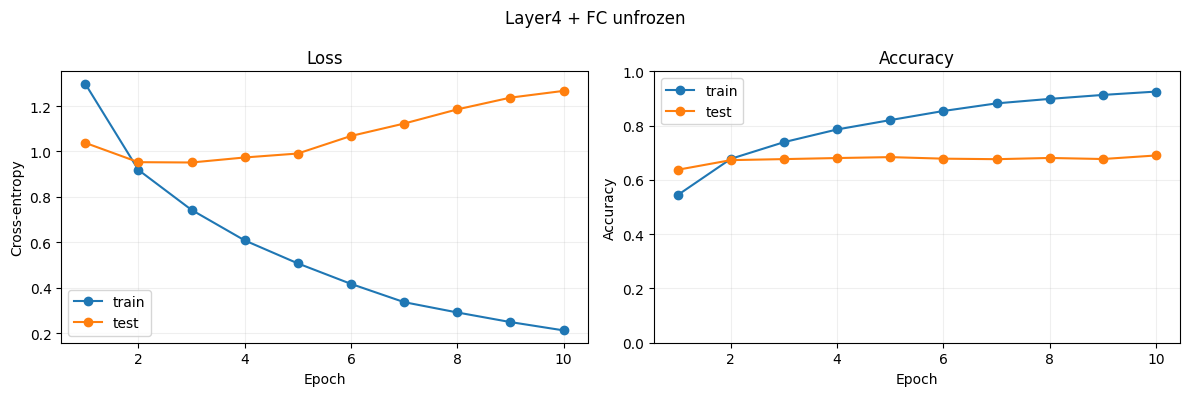

Accuracy: 69.00%


0.69

In [18]:
resnet18_frz=new_resnet()
for p in resnet18_frz.parameters():p.requires_grad=False
for p in resnet18_frz.layer4.parameters():p.requires_grad=True
for p in resnet18_frz.fc.parameters():p.requires_grad=True
num_epochs=NUM_EPOCHS
optimizer_partial=torch.optim.Adam(filter(lambda p:p.requires_grad,resnet18_frz.parameters()),lr=LEARNING_RATE)
history_layer4=train(resnet18_frz,loss_fn,optimizer_partial,train_loader,test_loader,num_epochs,device)
plot_learning_curve(history_layer4,'Layer4 + FC unfrozen')
test_accuracy(resnet18_frz,test_loader)

Epoch 01/10: train loss 1.0843, acc 62.44%; validation loss 0.7851, acc 72.55%; 25.4s
Epoch 02/10: train loss 0.6681, acc 76.82%; validation loss 0.6971, acc 76.28%; 25.8s
Epoch 03/10: train loss 0.4935, acc 82.79%; validation loss 0.6884, acc 77.02%; 25.4s
Epoch 04/10: train loss 0.3611, acc 87.33%; validation loss 0.7340, acc 76.58%; 25.7s
Epoch 05/10: train loss 0.2590, acc 90.85%; validation loss 0.7945, acc 76.56%; 25.4s
Epoch 06/10: train loss 0.1886, acc 93.45%; validation loss 0.8442, acc 76.74%; 25.4s
Epoch 07/10: train loss 0.1430, acc 95.09%; validation loss 0.9043, acc 77.35%; 25.6s
Epoch 08/10: train loss 0.1258, acc 95.57%; validation loss 0.9467, acc 77.49%; 25.6s
Epoch 09/10: train loss 0.1106, acc 96.21%; validation loss 0.9607, acc 77.55%; 25.6s
Epoch 10/10: train loss 0.0889, acc 96.92%; validation loss 1.0055, acc 77.20%; 25.6s


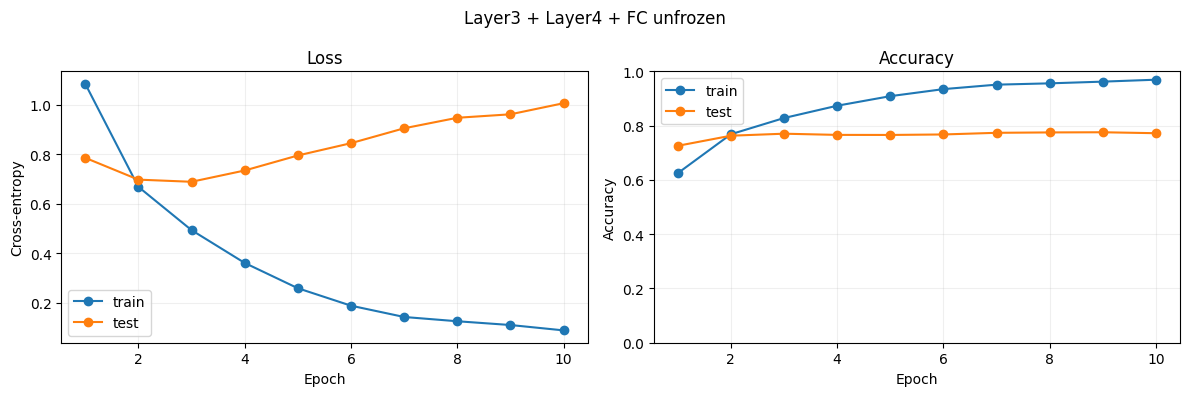

Accuracy: 77.20%
Compare candidate held-out accuracies: {'FC': 0.4594, 'layer4+FC': 0.69, 'layer3+4+FC': 0.772, 'all': 0.8196}


In [19]:
# Alternative: freeze stem, layer1, layer2; adapt layer3, layer4 and FC.
resnet18_frz=new_resnet()
for p in resnet18_frz.parameters():p.requires_grad=False
for block in (resnet18_frz.layer3,resnet18_frz.layer4,resnet18_frz.fc):
    for p in block.parameters():p.requires_grad=True
num_epochs=NUM_EPOCHS
optimizer_partial=torch.optim.Adam(filter(lambda p:p.requires_grad,resnet18_frz.parameters()),lr=LEARNING_RATE)
history_layer34=train(resnet18_frz,loss_fn,optimizer_partial,train_loader,test_loader,num_epochs,device)
plot_learning_curve(history_layer34,'Layer3 + Layer4 + FC unfrozen')
test_accuracy(resnet18_frz,test_loader)
print('Compare candidate held-out accuracies:',
      {name:round(h['test_acc'][-1],4) for name,h in
       [('FC',history_frozen),('layer4+FC',history_layer4),('layer3+4+FC',history_layer34),
        ('all',history_plain)]})


### ❓ **Q 3.2.11 Which layers did you freeze to yield the best performance vs training time balance? Can you give any intuition as to why this worked well? Compare it with unfreezing only the fc layer and explain why it performs better.**

**Answer:** Among the **partially frozen** models, freezing the stem and `layer1`–`layer2` while unfreezing **`layer3`, `layer4`, and `fc`** gave the best accuracy–time compromise in these results: **77.20%** test accuracy at about **25.5 seconds per epoch**. Training only `layer4` and `fc` achieved **69.00%** at about **23.3 seconds per epoch**, while training only `fc` gave **45.94%** at about **22 seconds per epoch**. Unfreezing `layer3` as well therefore improved accuracy by **31.26 percentage points** over `fc`-only, for about **3.5 extra seconds per epoch**. Earlier layers retain generic pretrained features; later layers can learn features better suited to CIFAR10. Full-network fine-tuning still achieved the higher accuracy (**81.96%**, about **28 seconds per epoch** without augmentation), so `layer3 + layer4 + fc` is a *compromise*, not the overall best-accuracy model. These comparisons use the notebook's reported test-set results, rather than a separate validation split.

___
___
# End of Phase 2 😊🥳